In [3]:
#import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tracks = pd.read_csv(
    "../data/raw/fma_metadata/tracks.csv",
    index_col=0,
    header=[0, 1]
)

In [4]:
tracks.shape

(106574, 52)

In [5]:
tracks.head()

album                                                     \
         comments         date_created        date_released engineer   
track_id                                                               
2               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
3               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
5               0  2008-11-26 01:44:45  2009-01-05 00:00:00      NaN   
10              0  2008-11-26 01:45:08  2008-02-06 00:00:00      NaN   
20              0  2008-11-26 01:45:05  2009-01-06 00:00:00      NaN   

                                                                          \
         favorites id                                information listens   
track_id                                                                   
2                4  1                                    <p></p>    6073   
3                4  1                                    <p></p>    6073   
5                4  1                                    <p></p>    6073   
10               4  6                                        NaN   47632   
20               2  4  <p> "spiritual songs" from Nicky Cook</p>    2710   

                        ...       track                         \
         producer tags  ... information interest language_code   
track_id                ...                                      
2             NaN   []  ...         NaN     4656            en   
3             NaN   []  ...         NaN     1470            en   
5             NaN   []  ...         NaN     1933            en   
10            NaN   []  ...         NaN    54881            en   
20            NaN   []  ...         NaN      978            en   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
2         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1293      NaN   
3         Attribution-NonCommercial-ShareAlike 3.0 Inter...     514      NaN   
5         Attribution-NonCommercial-ShareAlike 3.0 Inter...    1151      NaN   
10        Attribution-NonCommercial-NoDerivatives (aka M...   50135      NaN   
20        Attribution-NonCommercial-NoDerivatives (aka M...     361      NaN   

                                                 
         number publisher tags            title  
track_id                                         
2             3       NaN   []             Food  
3             4       NaN   []     Electric Ave  
5             6       NaN   []       This World  
10            1       NaN   []          Freeway  
20            3       NaN   []  Spiritual Level  

[5 rows x 52 columns]

In [6]:
tracks.columns

MultiIndex([( 'album',          'comments'),
            ( 'album',      'date_created'),
            ( 'album',     'date_released'),
            ( 'album',          'engineer'),
            ( 'album',         'favorites'),
            ( 'album',                'id'),
            ( 'album',       'information'),
            ( 'album',           'listens'),
            ( 'album',          'producer'),
            ( 'album',              'tags'),
            ( 'album',             'title'),
            ( 'album',            'tracks'),
            ( 'album',              'type'),
            ('artist', 'active_year_begin'),
            ('artist',   'active_year_end'),
            ('artist', 'associated_labels'),
            ('artist',               'bio'),
            ('artist',          'comments'),
            ('artist',      'date_created'),
            ('artist',         'favorites'),
            ('artist',                'id'),
            ('artist',          'latitude'),
          

In [7]:
tracks.info()

<class 'pandas.DataFrame'>
Index: 106574 entries, 2 to 155320
Data columns (total 52 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   (album, comments)            106574 non-null  int64  
 1   (album, date_created)        103045 non-null  str    
 2   (album, date_released)       70294 non-null   str    
 3   (album, engineer)            15295 non-null   str    
 4   (album, favorites)           106574 non-null  int64  
 5   (album, id)                  106574 non-null  int64  
 6   (album, information)         83149 non-null   str    
 7   (album, listens)             106574 non-null  int64  
 8   (album, producer)            18060 non-null   str    
 9   (album, tags)                106574 non-null  str    
 10  (album, title)               105549 non-null  str    
 11  (album, tracks)              106574 non-null  int64  
 12  (album, type)                100066 non-null  str    
 13  (artist, active

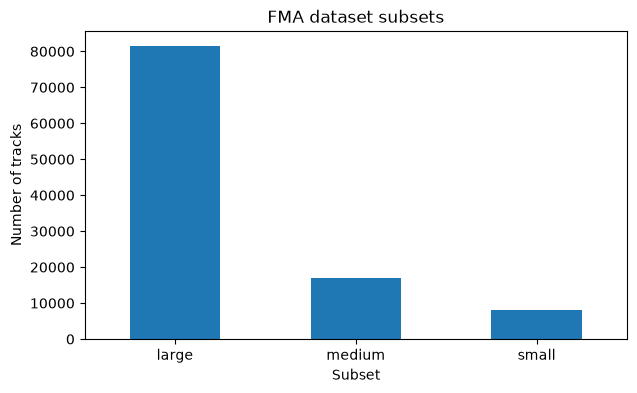

In [8]:
tracks[("set", "subset")].value_counts()

subset_counts = tracks[("set", "subset")].value_counts()

subset_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("FMA dataset subsets")
plt.xlabel("Subset")
plt.ylabel("Number of tracks")
plt.xticks(rotation=0)
plt.show()

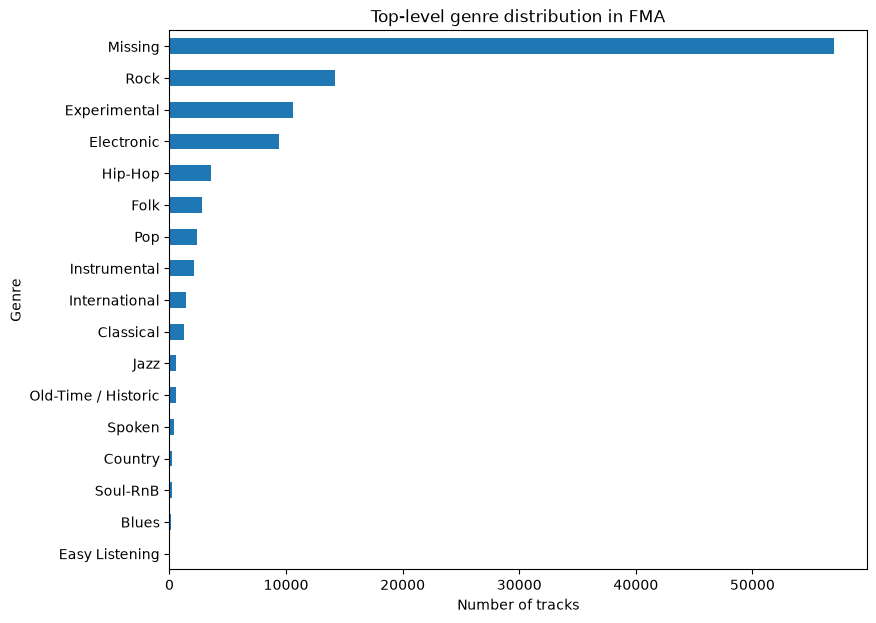

In [9]:
tracks[("track", "genre_top")].value_counts(dropna=False)

genre_counts = (
    tracks[("track", "genre_top")]
    .fillna("Missing")
    .value_counts()
)

genre_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 7)
)

plt.title("Top-level genre distribution in FMA")
plt.xlabel("Number of tracks")
plt.ylabel("Genre")
plt.show()

In [10]:
tracks[
    [
        ("artist", "name"),
        ("track", "title"),
        ("track", "genre_top"),
        ("track", "genres_all"),
        ("set", "subset"),
    ]
].head(20)

artist                       track  \
                                     name                       title   
track_id                                                                
2                                    AWOL                        Food   
3                                    AWOL                Electric Ave   
5                                    AWOL                  This World   
10                              Kurt Vile                     Freeway   
20                             Nicky Cook             Spiritual Level   
26                             Nicky Cook         Where is your Love?   
30                             Nicky Cook                   Too Happy   
46                             Nicky Cook                    Yosemite   
48                             Nicky Cook              Light of Light   
134                                  AWOL                Street Music   
135                              Abominog                Father's Day   
136                              Abominog  Peel Back The Mountain Sky   
137                                Airway                      Side A   
138                                Airway                      Side B   
139       Alec K. Redfearn & the Eyesores                    CandyAss   
140       Alec K. Redfearn & the Eyesores          Queen Of The Wires   
141       Alec K. Redfearn & the Eyesores                        Ohio   
142       Alec K. Redfearn & the Eyesores        Punjabi Watery Grave   
144                      Amoebic Ensemble                     Wire Up   
145                      Amoebic Ensemble                  Amoebiasis   

                                              set  
             genre_top         genres_all  subset  
track_id                                           
2              Hip-Hop               [21]   small  
3              Hip-Hop               [21]  medium  
5              Hip-Hop               [21]   small  
10                 Pop               [10]   small  
20                 NaN  [17, 10, 76, 103]   large  
26                 NaN  [17, 10, 76, 103]   large  
30                 NaN  [17, 10, 76, 103]   large  
46                 NaN  [17, 10, 76, 103]   large  
48                 NaN  [17, 10, 76, 103]   large  
134            Hip-Hop               [21]  medium  
135               Rock       [58, 12, 45]   large  
136               Rock       [58, 12, 45]  medium  
137       Experimental        [32, 1, 38]   large  
138       Experimental        [32, 1, 38]   large  
139               Folk               [17]  medium  
140               Folk               [17]   small  
141               Folk               [17]   small  
142               Folk               [17]   large  
144               Jazz                [4]   large  
145               Jazz                [4]   large

In [11]:
features = pd.read_csv(
    "../data/raw/fma_metadata/features.csv",
    index_col=0,
    header=[0, 1, 2]
)

In [12]:
features.shape

(106574, 518)

In [13]:
features.head()

feature    chroma_cens                                                    \
statistics    kurtosis                                                     
number              01        02        03        04        05        06   
track_id                                                                   
2             7.180653  5.230309  0.249321  1.347620  1.482478  0.531371   
3             1.888963  0.760539  0.345297  2.295201  1.654031  0.067592   
5             0.527563 -0.077654 -0.279610  0.685883  1.937570  0.880839   
10            3.702245 -0.291193  2.196742 -0.234449  1.367364  0.998411   
20           -0.193837 -0.198527  0.201546  0.258556  0.775204  0.084794   

feature                                             ...   tonnetz            \
statistics                                          ...       std             
number            07        08        09        10  ...        04        05   
track_id                                            ...                       
2           1.481593  2.691455  0.866868  1.341231  ...  0.054125  0.012226   
3           1.366848  1.054094  0.108103  0.619185  ...  0.063831  0.014212   
5          -0.923192 -0.927232  0.666617  1.038546  ...  0.040730  0.012691   
10          1.770694  1.604566  0.521217  1.982386  ...  0.074358  0.017952   
20         -0.289294 -0.816410  0.043851 -0.804761  ...  0.095003  0.022492   

feature                     zcr                                          \
statistics             kurtosis       max      mean    median       min   
number            06         01        01        01        01        01   
track_id                                                                  
2           0.012111   5.758890  0.459473  0.085629  0.071289  0.000000   
3           0.017740   2.824694  0.466309  0.084578  0.063965  0.000000   
5           0.014759   6.808415  0.375000  0.053114  0.041504  0.000000   
10          0.013921  21.434212  0.452148  0.077515  0.071777  0.000000   
20          0.021355  16.669037  0.469727  0.047225  0.040039  0.000977   

feature                         
statistics      skew       std  
number            01        01  
track_id                        
2           2.089872  0.061448  
3           1.716724  0.069330  
5           2.193303  0.044861  
10          3.542325  0.040800  
20          3.189831  0.030993  

[5 rows x 518 columns]

In [14]:
features.columns[:30]

MultiIndex([('chroma_cens', 'kurtosis', '01'),
            ('chroma_cens', 'kurtosis', '02'),
            ('chroma_cens', 'kurtosis', '03'),
            ('chroma_cens', 'kurtosis', '04'),
            ('chroma_cens', 'kurtosis', '05'),
            ('chroma_cens', 'kurtosis', '06'),
            ('chroma_cens', 'kurtosis', '07'),
            ('chroma_cens', 'kurtosis', '08'),
            ('chroma_cens', 'kurtosis', '09'),
            ('chroma_cens', 'kurtosis', '10'),
            ('chroma_cens', 'kurtosis', '11'),
            ('chroma_cens', 'kurtosis', '12'),
            ('chroma_cens',      'max', '01'),
            ('chroma_cens',      'max', '02'),
            ('chroma_cens',      'max', '03'),
            ('chroma_cens',      'max', '04'),
            ('chroma_cens',      'max', '05'),
            ('chroma_cens',      'max', '06'),
            ('chroma_cens',      'max', '07'),
            ('chroma_cens',      'max', '08'),
            ('chroma_cens',      'max', '09'),
            (

In [15]:
features.columns.get_level_values("feature").unique()

# These describe different aspects of the sound — harmony, timbre, spectral character, etc.

Index(['chroma_cens', 'chroma_cqt', 'chroma_stft', 'mfcc', 'rmse',
       'spectral_bandwidth', 'spectral_centroid', 'spectral_contrast',
       'spectral_rolloff', 'tonnetz', 'zcr'],
      dtype='str', name='feature')

In [16]:
features.isna().sum().sum()

np.int64(0)

The data available in FMA can easily support our baseline model. There is currently no need for embeddings, we can use the aspects of the sound to discover which tracks are acoustically similar and dissimilar

FMA track
     ↓
518 audio features
     ↓
standardise values
     ↓
cosine similarity
     ↓
nearest tracks

In [17]:
small_tracks = tracks[tracks[("set", "subset")] == "small"].copy()

small_tracks.shape

(8000, 52)

In [18]:
small_features = features.loc[small_tracks.index].copy()

small_features.shape

(8000, 518)

In [19]:
small_features.isna().sum().sum()

np.int64(0)

In [20]:
small_features.describe()

feature     chroma_cens                                                      \
statistics     kurtosis                                                       
number               01           02           03           04           05   
count       8000.000000  8000.000000  8000.000000  8000.000000  8000.000000   
mean           0.111983     0.007180     0.200494     0.005261     0.067485   
std            1.656377     1.934319     6.073813     1.288859     1.636802   
min           -1.803165    -1.816620    -1.825738    -1.760243    -1.781202   
25%           -0.695236    -0.732614    -0.691606    -0.698568    -0.722502   
50%           -0.225979    -0.288605    -0.217185    -0.265719    -0.267887   
75%            0.426059     0.326636     0.447804     0.339266     0.387846   
max           42.851593    79.781960   517.172424    26.313240    43.405674   

feature                                                                      \
statistics                                                                    
number               06           07           08           09           10   
count       8000.000000  8000.000000  8000.000000  8000.000000  8000.000000   
mean           0.077369     0.021349     0.139799     0.012609     0.091662   
std            1.599574     2.086226     2.983964     1.810619     1.984203   
min           -1.718097    -1.778957    -1.745497    -1.802878    -1.787692   
25%           -0.695780    -0.738476    -0.696258    -0.734161    -0.724942   
50%           -0.230598    -0.309080    -0.241916    -0.306807    -0.255516   
75%            0.411859     0.323601     0.434207     0.324868     0.402692   
max           47.604107   101.148888   188.753738    74.518082    75.878792   

feature     ...      tonnetz                                    zcr  \
statistics  ...          std                               kurtosis   
number      ...           04           05           06           01   
count       ...  8000.000000  8000.000000  8000.000000  8000.000000   
mean        ...     0.103515     0.021801     0.022063    31.577011   
std         ...     0.036906     0.005843     0.005811    70.380338   
min         ...     0.014479     0.006234     0.006667    -1.790083   
25%         ...     0.076203     0.017550     0.017851     4.452607   
50%         ...     0.099103     0.020881     0.021280    12.284789   
75%         ...     0.125883     0.025197     0.025516    32.293960   
max         ...     0.279182     0.058427     0.071633  1575.385254   

feature                                                                      \
statistics          max         mean       median          min         skew   
number               01           01           01           01           01   
count       8000.000000  8000.000000  8000.000000  8000.000000  8000.000000   
mean           0.395773     0.050856     0.041552     0.002503     3.519118   
std            0.185470     0.028484     0.027080     0.004689     2.962467   
min            0.032715     0.003490     0.000000     0.000000    -3.143864   
25%            0.261719     0.032412     0.024414     0.000000     1.647383   
50%            0.368652     0.046102     0.036621     0.000977     2.721854   
75%            0.482422     0.062770     0.052246     0.003418     4.601721   
max            0.999512     0.629665     0.749512     0.170898    36.000904   

feature                  
statistics          std  
number               01  
count       8000.000000  
mean           0.040383  
std            0.025868  
min            0.002608  
25%            0.022612  
50%            0.033839  
75%            0.051452  
max            0.317725  

[8 rows x 518 columns]

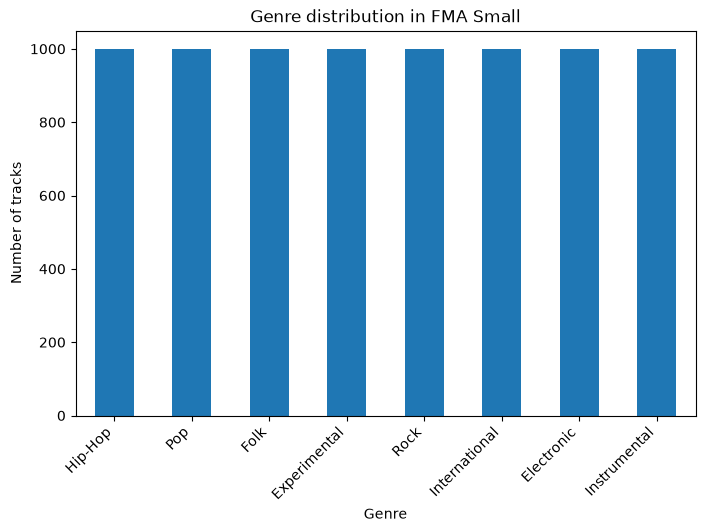

In [21]:
small_tracks = tracks[
    tracks[("set", "subset")] == "small"
].copy()

small_genres = (
    small_tracks[("track", "genre_top")]
    .fillna("Missing")
    .value_counts()
)

small_genres.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Genre distribution in FMA Small")
plt.xlabel("Genre")
plt.ylabel("Number of tracks")
plt.xticks(rotation=45, ha="right")
plt.show()

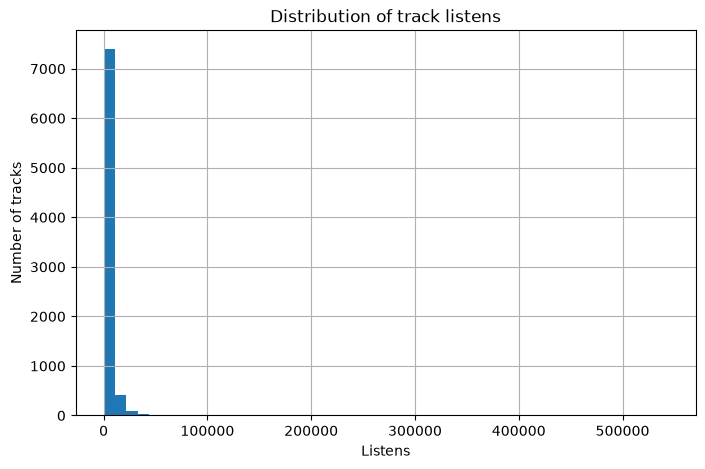

In [22]:
small_tracks[("track", "listens")].hist(
    bins=50,
    figsize=(8, 5)
)

plt.title("Distribution of track listens")
plt.xlabel("Listens")
plt.ylabel("Number of tracks")
plt.show()

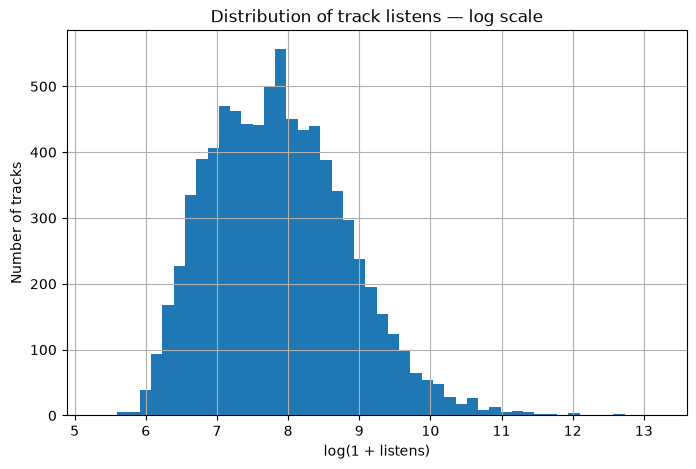

In [23]:
np.log1p(
    small_tracks[("track", "listens")]
).hist(
    bins=50,
    figsize=(8, 5)
)

plt.title("Distribution of track listens — log scale")
plt.xlabel("log(1 + listens)")
plt.ylabel("Number of tracks")
plt.show()

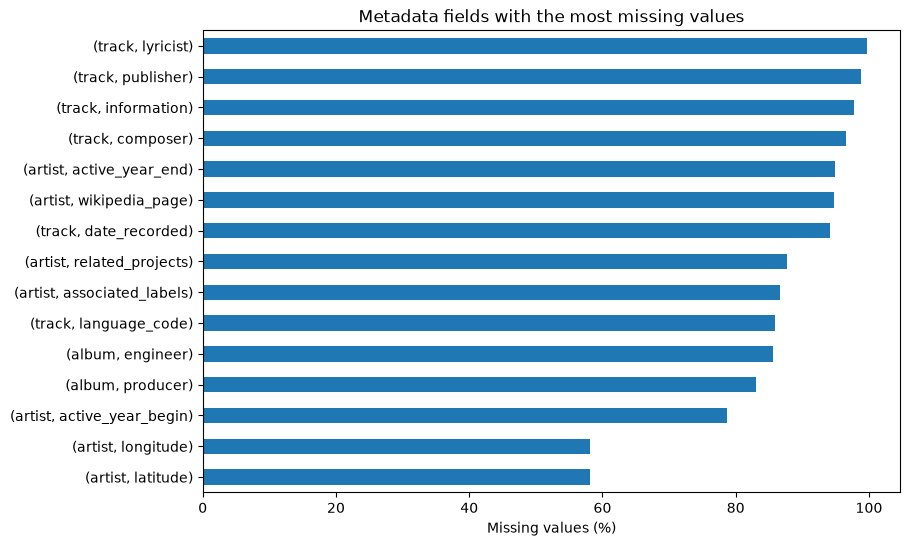

In [24]:
missing_pct = (
    tracks.isna().mean() * 100
).sort_values(ascending=False)

missing_pct.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Metadata fields with the most missing values")
plt.xlabel("Missing values (%)")
plt.show()

EDA findings
The FMA dataset contains 106,574 tracks, with 518 precomputed audio features per track.
For development, we use FMA Small (8,000 tracks) because it is manageable and balanced across 8 top-level genres.
genre_top is missing for roughly 53% of the full dataset, so it should not be the main recommendation feature. More detailed genres and genres_all fields are more complete.
The audio feature space is uneven: MFCC and chroma features dominate, meaning harmonic information may be overweighted relative to other characteristics.
Several features are strongly skewed and contain extreme outliers, so RobustScaler and alternative feature selections should be tested against the current StandardScaler approach.
PCA analysis shows that about 60 components preserve neighbourhood quality as well as the current 146-component solution, reducing dimensionality substantially without hurting performance.
Artist location is potentially useful for TasteBridge, but latitude/longitude are missing for around 58% of tracks. These values should be enriched from external metadata rather than statistically imputed.
Overall, FMA provides a strong basis for the first content-based recommender, while later TasteBridge stages can add metadata, location, novelty and user-controlled exploration.